In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("Actual Biophysical Signature Measurement and Extracted Data.xlsx")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Actual Biophysical Signature Measurement and Extracted Data.xlsx'

In [ ]:
df.columns

Index(['Filename', 'Day', 'LAI', 'GrowthStage', 'area', 'Filename.1', 'Day.1',
       'LAI.1', 'GrowthStage.1', 'area.1'],
      dtype='object')

In [ ]:
df.shape

(168, 10)

# COMBINE INDOOR AND OUTDOOR 

In [ ]:
indoor = df[['Filename', 'Day', 'LAI', 'GrowthStage']].copy()
indoor['Environment'] = 'Indoor'
indoor.head()

,Filename,Day,LAI,GrowthStage,Environment
0,IN_DAG0101.jpg,Day 1,0.032273,Vegetative,Indoor
1,IN_DAG0201.jpg,Day 2,0.036370,Vegetative,Indoor
2,IN_DAG0301.jpg,Day 3,0.002650,Vegetative,Indoor
3,IN_DAG0401.jpg,Day 4,0.003601,Vegetative,Indoor
4,IN_DAG0501.jpg,Day 5,0.003373,Vegetative,Indoor


In [ ]:
outdoor = df[['Filename.1', 'Day.1', 'LAI.1', 'GrowthStage.1']].copy()
outdoor.columns = ['Filename', 'Day', 'LAI', 'GrowthStage']
outdoor['Environment'] = 'Outdoor'
outdoor.head()

,Filename,Day,LAI,GrowthStage,Environment
0,OUT_DAG0101.jpg,Day 1,0.028344,Vegetative,Outdoor
1,OUT_DAG0201.jpg,Day 2,0.000504,Vegetative,Outdoor
2,OUT_DAG0301.jpg,Day 3,0.001093,Vegetative,Outdoor
3,OUT_DAG0401.jpg,Day 4,0.001909,Vegetative,Outdoor
4,OUT_DAG0501.jpg,Day 5,0.001110,Vegetative,Outdoor


In [ ]:
data = pd.concat([indoor, outdoor], ignore_index=True)
data.head()

,Filename,Day,LAI,GrowthStage,Environment
0,IN_DAG0101.jpg,Day 1,0.032273,Vegetative,Indoor
1,IN_DAG0201.jpg,Day 2,0.036370,Vegetative,Indoor
2,IN_DAG0301.jpg,Day 3,0.002650,Vegetative,Indoor
3,IN_DAG0401.jpg,Day 4,0.003601,Vegetative,Indoor
4,IN_DAG0501.jpg,Day 5,0.003373,Vegetative,Indoor


In [ ]:
data.shape

(336, 5)

# CLEAN VALUES

In [ ]:
data['LAI'] = pd.to_numeric(data['LAI'], errors='coerce')
data['GrowthStage'] = data['GrowthStage'].astype(str).str.strip()
data = data.dropna(subset=['LAI', 'GrowthStage'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Filename     336 non-null    object 
 1   Day          336 non-null    object 
 2   LAI          336 non-null    float64
 3   GrowthStage  336 non-null    object 
 4   Environment  336 non-null    object 
dtypes: float64(1), object(4)
memory usage: 13.3+ KB


In [ ]:
data['GrowthStage'].value_counts()
data['GrowthStage'].unique()

array(['Vegetative', 'HeadDevelopment', 'Harvest'], dtype=object)

In [ ]:
data['Environment'].value_counts()

Environment
Indoor     168
Outdoor    168
Name: count, dtype: int64

In [ ]:
pd.crosstab(data['GrowthStage'], data['Environment'])

Environment,Indoor,Outdoor
GrowthStage,,
Harvest,28,28
HeadDevelopment,84,84
Vegetative,56,56


In [ ]:
stage_stats = (
    data.groupby('GrowthStage')['LAI']
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
    .round(5)
)

stage_stats

,Count,Mean,Median,Std,Min,Max
GrowthStage,,,,,,
Harvest,56,0.04913,0.06073,0.03111,0.00846,0.10537
HeadDevelopment,168,0.03278,0.02694,0.03002,0.00055,0.12925
Vegetative,112,0.00832,0.00473,0.00888,0.00048,0.03752


<Figure size 800x500 with 0 Axes>

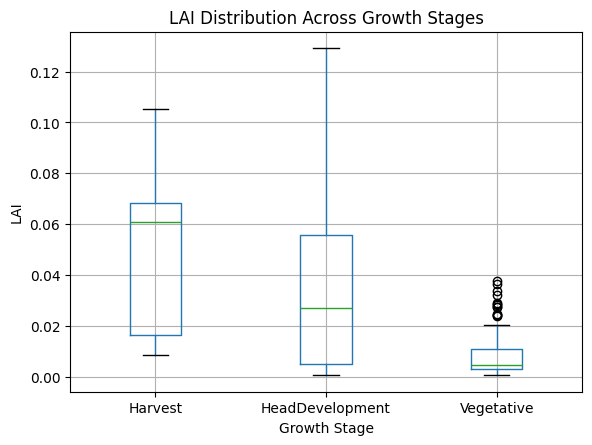

In [ ]:
plt.figure(figsize=(8, 5))

data.boxplot(
    column='LAI',
    by='GrowthStage'
)

plt.title('LAI Distribution Across Growth Stages')
plt.suptitle('')
plt.xlabel('Growth Stage')
plt.ylabel('LAI')

plt.show()

In [ ]:
stage_percentiles = (
    data.groupby('GrowthStage')['LAI']
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .round(5)
)

stage_percentiles

,0.25,0.50,0.75
GrowthStage,,,
Harvest,0.01645,0.06073,0.06842
HeadDevelopment,0.00505,0.02694,0.05573
Vegetative,0.00290,0.00473,0.01082


In [ ]:
environment_stats = (
    data.groupby(['GrowthStage', 'Environment'])['LAI']
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
    .round(5)
)

environment_stats

Count     Mean   Median      Std      Min  \
GrowthStage     Environment                                              
Harvest         Indoor          28  0.07495  0.06842  0.01631  0.04916   
                Outdoor         28  0.02330  0.01623  0.01795  0.00846   
HeadDevelopment Indoor          84  0.05863  0.05576  0.02037  0.02041   
                Outdoor         84  0.00693  0.00500  0.00678  0.00055   
Vegetative      Indoor          56  0.01160  0.00775  0.00983  0.00090   
                Outdoor         56  0.00503  0.00331  0.00636  0.00048   

                                 Max  
GrowthStage     Environment           
Harvest         Indoor       0.10537  
                Outdoor      0.06492  
HeadDevelopment Indoor       0.12925  
                Outdoor      0.04401  
Vegetative      Indoor       0.03752  
                Outdoor      0.02834

In [ ]:
stage_percentiles = (
    data.groupby('GrowthStage')['LAI']
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .round(5)
)

stage_percentiles

,0.25,0.50,0.75
GrowthStage,,,
Harvest,0.01645,0.06073,0.06842
HeadDevelopment,0.00505,0.02694,0.05573
Vegetative,0.00290,0.00473,0.01082


In [ ]:
environment_stats = (
    data.groupby(['GrowthStage', 'Environment'])['LAI']
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
    .round(5)
)

environment_stats

Count     Mean   Median      Std      Min  \
GrowthStage     Environment                                              
Harvest         Indoor          28  0.07495  0.06842  0.01631  0.04916   
                Outdoor         28  0.02330  0.01623  0.01795  0.00846   
HeadDevelopment Indoor          84  0.05863  0.05576  0.02037  0.02041   
                Outdoor         84  0.00693  0.00500  0.00678  0.00055   
Vegetative      Indoor          56  0.01160  0.00775  0.00983  0.00090   
                Outdoor         56  0.00503  0.00331  0.00636  0.00048   

                                 Max  
GrowthStage     Environment           
Harvest         Indoor       0.10537  
                Outdoor      0.06492  
HeadDevelopment Indoor       0.12925  
                Outdoor      0.04401  
Vegetative      Indoor       0.03752  
                Outdoor      0.02834

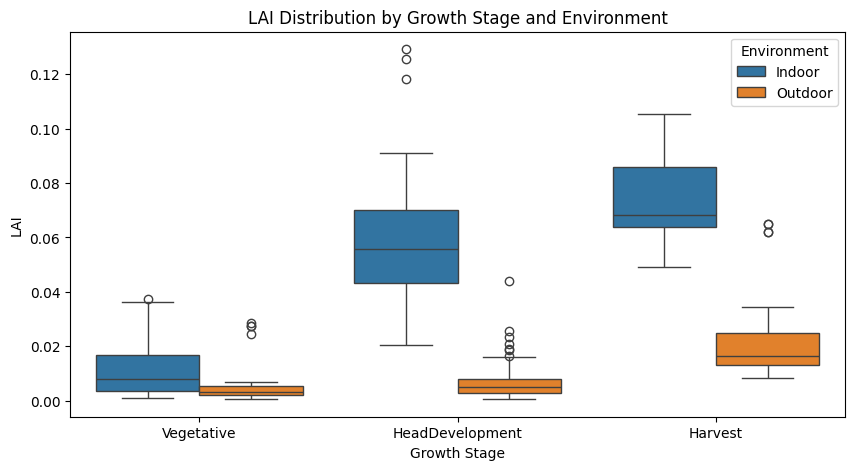

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=data,
    x='GrowthStage',
    y='LAI',
    hue='Environment'
)

plt.title('LAI Distribution by Growth Stage and Environment')
plt.xlabel('Growth Stage')
plt.ylabel('LAI')

plt.show()

# LAI → Crop Development

In [ ]:
stage_environment_mean = (
    data.groupby(['Environment', 'GrowthStage'])['LAI']
    .mean()
    .unstack()
    .round(5)
)

stage_environment_mean

GrowthStage,Harvest,HeadDevelopment,Vegetative
Environment,,,
Indoor,0.07495,0.05863,0.01160
Outdoor,0.02330,0.00693,0.00503


In [ ]:
stage_order = {
    'Vegetative': 1,
    'HeadDevelopment': 2,
    'Harvest': 3
}

data['StageOrder'] = data['GrowthStage'].map(stage_order)

data[['GrowthStage', 'StageOrder']].drop_duplicates()

,GrowthStage,StageOrder
0,Vegetative,1
14,HeadDevelopment,2
35,Harvest,3


In [ ]:
data[['LAI', 'StageOrder']].corr()

,LAI,StageOrder
LAI,1.000000,0.498685
StageOrder,0.498685,1.000000


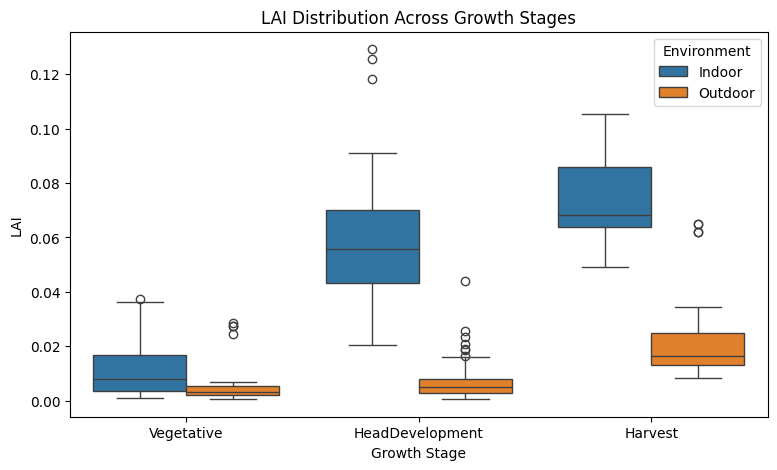

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x='GrowthStage',
    y='LAI',
    hue='Environment'
)

plt.title('LAI Distribution Across Growth Stages')
plt.xlabel('Growth Stage')
plt.ylabel('LAI')

plt.show()

# LAI-Based Crop Development / Water-Demand Indicator

In [ ]:
reference_thresholds = {
    'Indoor': {
        'low_to_moderate': data.loc[
            data['Environment'] == 'Indoor', 'LAI'
        ].quantile(0.33),

        'moderate_to_high': data.loc[
            data['Environment'] == 'Indoor', 'LAI'
        ].quantile(0.66)
    },

    'Outdoor': {
        'low_to_moderate': data.loc[
            data['Environment'] == 'Outdoor', 'LAI'
        ].quantile(0.33),

        'moderate_to_high': data.loc[
            data['Environment'] == 'Outdoor', 'LAI'
        ].quantile(0.66)
    }
}

reference_thresholds

{'Indoor': {'low_to_moderate': np.float64(0.03198098809027777),
  'moderate_to_high': np.float64(0.05980945243055554)},
 'Outdoor': {'low_to_moderate': np.float64(0.0032416127430555555),
  'moderate_to_high': np.float64(0.007220901041666666)}}

In [ ]:
threshold_table = pd.DataFrame({
    'Environment': ['Indoor', 'Outdoor'],
    'Low_to_Moderate': [
        reference_thresholds['Indoor']['low_to_moderate'],
        reference_thresholds['Outdoor']['low_to_moderate']
    ],
    'Moderate_to_High': [
        reference_thresholds['Indoor']['moderate_to_high'],
        reference_thresholds['Outdoor']['moderate_to_high']
    ]
})

threshold_table.round(5)

,Environment,Low_to_Moderate,Moderate_to_High
0,Indoor,0.03198,0.05981
1,Outdoor,0.00324,0.00722


In [ ]:
def decision_engine(predicted_lai, environment):
    
    # Check environment
    if environment not in reference_thresholds:
        return {
            'LAI': predicted_lai,
            'Environment': environment,
            'WaterDemand': 'Unknown',
            'Decision': 'Environment not supported'
        }
    
    # Get thresholds for the environment
    thresholds = reference_thresholds[environment]
    
    low_threshold = thresholds['low_to_moderate']
    high_threshold = thresholds['moderate_to_high']
    
    # Determine demand class
    if predicted_lai < low_threshold:
        demand = 'Low'
        
    elif predicted_lai < high_threshold:
        demand = 'Moderate'
        
    else:
        demand = 'High'
    
    # Final decision
    if demand == 'Low':
        decision = 'Lower relative water demand'
        
    elif demand == 'Moderate':
        decision = 'Moderate relative water demand'
        
    else:
        decision = 'Higher relative water demand'
    
    return {
        'LAI': predicted_lai,
        'Environment': environment,
        'WaterDemand': demand,
        'Decision': decision
    }

In [ ]:
test_cases = [
    (0.005, 'Indoor'),
    (0.040, 'Indoor'),
    (0.075, 'Indoor'),
    (0.002, 'Outdoor'),
    (0.010, 'Outdoor'),
    (0.030, 'Outdoor')
]

for lai, environment in test_cases:
    
    result = decision_engine(lai, environment)
    
    print(result)

{'LAI': 0.005, 'Environment': 'Indoor', 'WaterDemand': 'Low', 'Decision': 'Lower relative water demand'}
{'LAI': 0.04, 'Environment': 'Indoor', 'WaterDemand': 'Moderate', 'Decision': 'Moderate relative water demand'}
{'LAI': 0.075, 'Environment': 'Indoor', 'WaterDemand': 'High', 'Decision': 'Higher relative water demand'}
{'LAI': 0.002, 'Environment': 'Outdoor', 'WaterDemand': 'Low', 'Decision': 'Lower relative water demand'}
{'LAI': 0.01, 'Environment': 'Outdoor', 'WaterDemand': 'High', 'Decision': 'Higher relative water demand'}
{'LAI': 0.03, 'Environment': 'Outdoor', 'WaterDemand': 'High', 'Decision': 'Higher relative water demand'}


In [ ]:
data['FinalWaterDemand'] = data.apply(
    lambda row: decision_engine(
        row['LAI'],
        row['Environment']
    )['WaterDemand'],
    axis=1
)

data[
    ['Environment', 'GrowthStage', 'LAI', 'FinalWaterDemand']
].head(20)

,Environment,GrowthStage,LAI,FinalWaterDemand
0,Indoor,Vegetative,0.032273,Moderate
1,Indoor,Vegetative,0.036370,Moderate
2,Indoor,Vegetative,0.002650,Low
3,Indoor,Vegetative,0.003601,Low
4,Indoor,Vegetative,0.003373,Low
5,Indoor,Vegetative,0.005458,Low
6,Indoor,Vegetative,0.006119,Low
7,Indoor,Vegetative,0.012093,Low
8,Indoor,Vegetative,0.010679,Low
9,Indoor,Vegetative,0.012026,Low


In [ ]:
final_validation = pd.crosstab(
    [data['Environment'], data['GrowthStage']],
    data['FinalWaterDemand'],
    normalize='index'
).round(3)

final_validation

FinalWaterDemand              High    Low  Moderate
Environment GrowthStage                            
Indoor      Harvest          0.893  0.000     0.107
            HeadDevelopment  0.381  0.048     0.571
            Vegetative       0.000  0.929     0.071
Outdoor     Harvest          1.000  0.000     0.000
            HeadDevelopment  0.298  0.345     0.357
            Vegetative       0.071  0.482     0.446

In [ ]:
data[['Filename', 'Day', 'LAI', 'GrowthStage', 'Environment']].head(20)

,Filename,Day,LAI,GrowthStage,Environment
0,IN_DAG0101.jpg,Day 1,0.032273,Vegetative,Indoor
1,IN_DAG0201.jpg,Day 2,0.036370,Vegetative,Indoor
2,IN_DAG0301.jpg,Day 3,0.002650,Vegetative,Indoor
3,IN_DAG0401.jpg,Day 4,0.003601,Vegetative,Indoor
4,IN_DAG0501.jpg,Day 5,0.003373,Vegetative,Indoor
5,IN_DAG0601.jpg,Day 6,0.005458,Vegetative,Indoor
6,IN_DAG0701.jpg,Day 7,0.006119,Vegetative,Indoor
7,IN_DAG0801.jpg,Day 8,0.012093,Vegetative,Indoor
8,IN_DAG0901.jpg,Day 9,0.010679,Vegetative,Indoor
9,IN_DAG1001.jpg,Day 10,0.012026,Vegetative,Indoor


In [ ]:
data['Day'].unique()

array(['Day 1', 'Day 2', 'Day 3', 'Day 4', 'Day 5', 'Day 6', 'Day 7',
       'Day 8', 'Day 9', 'Day 10', 'Day 11', 'Day 12', 'Day 13', 'Day 14',
       'Day 15', 'Day 16', 'Day 17', 'Day 18', 'Day 19', 'Day 20',
       'Day 21', 'Day 22', 'Day 23', 'Day 24', 'Day 25', 'Day 26',
       'Day 27', 'Day 28', 'Day 29', 'Day 30', 'Day 31', 'Day 32',
       'Day 33', 'Day 34', 'Day 35', 'Day 36', 'Day 37', 'Day 38',
       'Day 39', 'Day 40', 'Day 41', 'Day 42'], dtype=object)

In [ ]:
def classify_lai(predicted_lai, environment):
    if environment not in reference_thresholds:
        return 'Unknown'

    thresholds = reference_thresholds[environment]

    if predicted_lai < thresholds['low_to_moderate']:
        return 'Low'
    elif predicted_lai < thresholds['moderate_to_high']:
        return 'Moderate'
    else:
        return 'High'

In [ ]:
print(classify_lai(0.01, 'Indoor'))
print(classify_lai(0.04, 'Indoor'))
print(classify_lai(0.07, 'Indoor'))

Low
Moderate
High


In [ ]:
def irrigation_decision(predicted_lai, environment, eto, rainfall):

    # 1. Classify crop demand from LAI
    lai_demand = classify_lai(predicted_lai, environment)

    # 2. Classify atmospheric demand from ET0
    eto_demand = classify_eto(eto)

    # 3. Take the higher of the two demands
    demand_level = {
        'Low': 1,
        'Moderate': 2,
        'High': 3
    }

    combined_level = max(
        demand_level[lai_demand],
        demand_level[eto_demand]
    )

    if combined_level == 1:
        combined_demand = 'Low'
    elif combined_level == 2:
        combined_demand = 'Moderate'
    else:
        combined_demand = 'High'

    # 4. Adjust for meaningful rainfall
    final_demand = adjust_for_rainfall(
        combined_demand,
        rainfall
    )

    return {
        'LAI': predicted_lai,
        'LAI_Demand': lai_demand,
        'ET0': eto,
        'ET0_Demand': eto_demand,
        'Rainfall': rainfall,
        'Final_Irrigation_Demand': final_demand
    }

In [ ]:
def classify_eto(eto):

    if eto < 2.231133901283059:
        return 'Low'
    elif eto < 5.158432087433082:
        return 'Moderate'
    else:
        return 'High'

In [ ]:
rain_threshold = 2.7575

def adjust_for_rainfall(demand, rainfall):

    if rainfall >= rain_threshold:
        if demand == 'High':
            return 'Moderate'
        elif demand == 'Moderate':
            return 'Low'
        else:
            return 'Low'

    return demand

In [ ]:
irrigation_decision(
    predicted_lai=0.07,
    environment='Indoor',
    eto=6.5,
    rainfall=0
)

{'LAI': 0.07,
 'LAI_Demand': 'High',
 'ET0': 6.5,
 'ET0_Demand': 'High',
 'Rainfall': 0,
 'Final_Irrigation_Demand': 'High'}

In [ ]:
test_cases = [
    # Low crop demand + low weather demand + no rain
    (0.01, 'Indoor', 1.5, 0),

    # High crop demand + high weather demand + no rain
    (0.07, 'Indoor', 6.5, 0),

    # High crop demand + high weather demand + meaningful rain
    (0.07, 'Indoor', 6.5, 10),

    # Low crop demand + high weather demand + no rain
    (0.01, 'Indoor', 7.0, 0),

    # High crop demand + low weather demand + no rain
    (0.07, 'Indoor', 1.5, 0),

    # Moderate conditions + meaningful rain
    (0.04, 'Indoor', 3.5, 5)
]

for case in test_cases:
    print(irrigation_decision(*case))

{'LAI': 0.01, 'LAI_Demand': 'Low', 'ET0': 1.5, 'ET0_Demand': 'Low', 'Rainfall': 0, 'Final_Irrigation_Demand': 'Low'}
{'LAI': 0.07, 'LAI_Demand': 'High', 'ET0': 6.5, 'ET0_Demand': 'High', 'Rainfall': 0, 'Final_Irrigation_Demand': 'High'}
{'LAI': 0.07, 'LAI_Demand': 'High', 'ET0': 6.5, 'ET0_Demand': 'High', 'Rainfall': 10, 'Final_Irrigation_Demand': 'Moderate'}
{'LAI': 0.01, 'LAI_Demand': 'Low', 'ET0': 7.0, 'ET0_Demand': 'High', 'Rainfall': 0, 'Final_Irrigation_Demand': 'High'}
{'LAI': 0.07, 'LAI_Demand': 'High', 'ET0': 1.5, 'ET0_Demand': 'Low', 'Rainfall': 0, 'Final_Irrigation_Demand': 'High'}
{'LAI': 0.04, 'LAI_Demand': 'Moderate', 'ET0': 3.5, 'ET0_Demand': 'Moderate', 'Rainfall': 5, 'Final_Irrigation_Demand': 'Low'}
